**Chiller Digital Twin 3: Fouling Soft Sensor**

Fouling cannot be measured directly, but its effects can: a higher condensing pressure and discharge temperature, a smaller cooling water temperature rise and more compressor power. A **soft sensor** uses the model to work backwards from these measurements to the fouling resistance. This is the core of a digital twin: the model is fitted to the plant, and the fitted parameters tell us the condition of the equipment.

### Method:

1. **Plant data**: here generated by the twin itself at a hidden fouling resistance that grows over time, with measurement noise added:

| Measurement | Noise (standard deviation) |
|---|---|
| Condensing pressure | 0.02 bar |
| Compressor discharge temperature | 0.2 °C |
| Cooling water outlet temperature | 0.05 °C |
| Compressor power | 0.03 kW |

2. **Parameter estimation**: the fouling resistance is freed in the IDAES model and chosen to minimize the noise-weighted squared differences between the model and the measurements,
$$\min_{R_f} \sum_i \left(\frac{y_i^{model}(R_f) - y_i^{measured}}{\sigma_i}\right)^2$$
3. **Alert**: when the estimated COP loss exceeds 5 %, the soft sensor raises a cleaning alert.

In [1]:
import idaes

print("IDAES version: ", idaes.__version__)

IDAES version:  2.13.0


In [2]:
from chiller import setup_chiller_model, chiller_results

# Build, initialize and solve the chiller at its design point
model, results = setup_chiller_model()
print(results.solver.termination_condition)
cop_clean = chiller_results(model)["COP"]
print("Design COP: {0:.3f}".format(cop_clean))

The DOF is 0
optimal
Design COP: 4.563


In [3]:
from chiller_case_studies import synthetic_measurements

true_fouling = [0, 0.0001, 0.0002, 0.0003, 0.0004, 0.0005]  # fouling grows between cleanings
measurements = synthetic_measurements(model, true_fouling, seed=0)
measurements

,True fouling (m2K/W),True COP,Condenser pressure (bar),Discharge temperature (C),Cooling water outlet (C),Compressor power (kW)
0,0.0000,4.563172,10.166598,56.616384,35.040792,4.593959
1,0.0001,4.420733,10.443656,57.956746,35.052931,4.720066
2,0.0002,4.284603,10.737446,58.871894,34.935163,4.793099
3,0.0003,4.154676,11.008350,60.317522,34.882318,4.869195
4,0.0004,4.030744,11.352945,61.527794,34.943213,5.020653
5,0.0005,3.912542,11.675457,63.085921,34.867153,5.096913


In [4]:
from chiller_case_studies import soft_sensor_study

estimates = soft_sensor_study(model, measurements, cop_clean, alert_cop_loss=0.05)
estimates

,True fouling (m2K/W),Estimated fouling (m2K/W),True COP,Estimated COP,COP loss (%),Cleaning alert
0,0.0000,4.184757e-07,4.563172,4.562563,0.013350,False
1,0.0001,9.887056e-05,4.420733,4.422306,3.087010,False
2,0.0002,1.934518e-04,4.284603,4.293325,5.913577,True
3,0.0003,2.862988e-04,4.154676,4.172118,8.569785,True
4,0.0004,3.975244e-04,4.030744,4.033741,11.602244,True
5,0.0005,5.025815e-04,3.912542,3.909564,14.323543,True


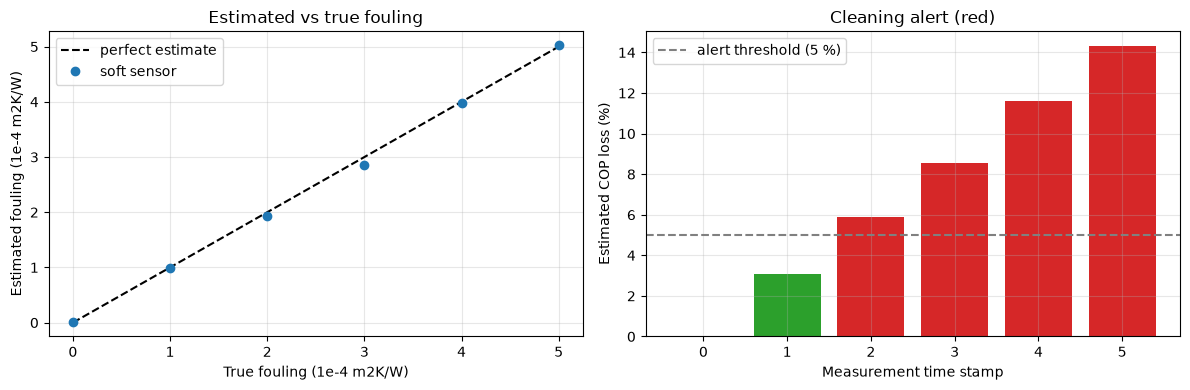

In [5]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(estimates["True fouling (m2K/W)"] * 1e4, estimates["True fouling (m2K/W)"] * 1e4, "k--", label="perfect estimate")
ax1.plot(estimates["True fouling (m2K/W)"] * 1e4, estimates["Estimated fouling (m2K/W)"] * 1e4, "o", label="soft sensor")
ax1.set_xlabel("True fouling (1e-4 m2K/W)")
ax1.set_ylabel("Estimated fouling (1e-4 m2K/W)")
ax1.set_title("Estimated vs true fouling")
ax1.grid(alpha=0.3)
ax1.legend()
colors = ["tab:red" if alert else "tab:green" for alert in estimates["Cleaning alert"]]
ax2.bar(range(len(estimates)), estimates["COP loss (%)"], color=colors)
ax2.axhline(5, color="grey", linestyle="--", label="alert threshold (5 %)")
ax2.set_xlabel("Measurement time stamp")
ax2.set_ylabel("Estimated COP loss (%)")
ax2.set_title("Cleaning alert (red)")
ax2.grid(alpha=0.3)
ax2.legend()
plt.tight_layout()
plt.show()